本 notebook 是 [M03.5 时间序列](../notes/05-time-series.qmd) 的实例讲解。

1. 1. 平稳 AR(1) 与样本自相关
2. 2. 趋势、季节项与过去窗口
3. 3. 对数时间与离线变化点
4. 4. 非均匀采样的频率分析

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.signal import lombscargle

from semiai.plotting import BLUE, GRAY, ORANGE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. 平稳 AR(1) 与样本自相关

从平稳初值模拟 AR(1)，检查方差和前几阶自相关与解析结果的关系。

样本方差/解析方差: 2.830839557525758 2.7777777777777786
   lag  sample ACF   theory
0    0    1.000000  1.00000
1    1    0.808943  0.80000
2    2    0.643165  0.64000
3    3    0.513782  0.51200
4    4    0.409197  0.40960
5    5    0.316808  0.32768
相关导致的渐近均值有效样本量: 1333.333333333333


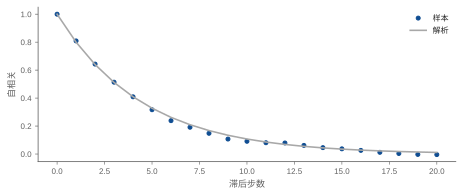

In [2]:
phi = 0.8
n = 12000
x = np.empty(n)
x[0] = rng.normal(0, 1 / np.sqrt(1 - phi**2))
for i in range(1, n):
    x[i] = phi * x[i - 1] + rng.normal()
centered = x - x.mean()
acf = np.correlate(centered[:3000], centered[:3000], mode="full")[2999:3020]
acf = acf / acf[0]
print("样本方差/解析方差:", x.var(), 1 / (1 - phi**2))
print(pd.DataFrame({"lag": np.arange(6), "sample ACF": acf[:6], "theory": phi ** np.arange(6)}))
print("相关导致的渐近均值有效样本量:", n * (1 - phi) / (1 + phi))
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot(np.arange(21), acf, "o", color=BLUE, label="样本")
ax.plot(np.arange(21), phi ** np.arange(21), color=GRAY, label="解析")
ax.set(xlabel="滞后步数", ylabel="自相关")
ax.legend()
fig.tight_layout()
plt.show()

读法：平稳不意味着独立；自相关衰减意味着均值方差大于独立抽样公式。有限样本 ACF 不会精确等于理论，尾部估计尤其不稳定。

## 2. 趋势、季节项与过去窗口

用已知周期的线性谐波回归分解信号，并检查预测特征只使用当前时刻之前的记录。

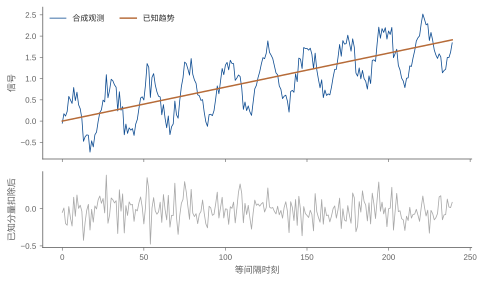

回归系数: [-0.00089913  0.00781485  0.62380838  0.01341889] 未来段 RMSE: 0.1467626809708939
           y      lag1  past_mean_12
12  0.062160  0.290453      0.382461
13 -0.476117  0.062160      0.391772
14 -0.369886 -0.476117      0.337685


In [3]:
t = np.arange(240)
trend = 0.008 * t
season = 0.6 * np.sin(2 * np.pi * t / 24)
y = trend + season + rng.normal(0, 0.16, len(t))
fig, axes = plt.subplots(2, 1, figsize=(6.8, 4), sharex=True, height_ratios=[2, 1])
axes[0].plot(t, y, color=BLUE, lw=0.8, label="合成观测")
axes[0].plot(t, trend, color=ORANGE, lw=1.5, label="已知趋势")
axes[0].set(ylabel="信号")
axes[0].legend(ncol=2)
axes[1].plot(t, y - trend - season, color=GRAY, lw=0.8)
axes[1].set(xlabel="等间隔时刻", ylabel="已知分量扣除后")
fig.tight_layout()
plt.show()

A = np.column_stack([np.ones(len(t)), t, np.sin(2 * np.pi * t / 24), np.cos(2 * np.pi * t / 24)])
train = t < 180
coef = np.linalg.lstsq(A[train], y[train], rcond=None)[0]
residual = y - A @ coef
print("回归系数:", coef, "未来段 RMSE:", np.sqrt(np.mean(residual[~train] ** 2)))
table = pd.DataFrame({"y": y})
table["lag1"] = table.y.shift(1)
table["past_mean_12"] = table.y.shift(1).rolling(12).mean()
print(table.iloc[12:15])
assert np.isclose(table.past_mean_12.iloc[12], y[:12].mean())

读法：这里周期已知、趋势线性，因而可用最小二乘隔离机制；真实数据需要在训练时间段决定周期和模型，扣除拟合分量不自动保证剩余项平稳。

## 3. 对数时间与离线变化点

在 log(t) 中构造连续斜率变化，比较固定预算的线性采样与对数采样；扫描候选折点并拟合两段连续直线。

In [4]:
def fit_break(times, signal):
    """合成无量纲 log-time 信号的单折点最小二乘扫描。"""
    u = np.log(times)
    candidates = np.linspace(np.log(3), np.log(300), 160)
    losses = []
    for point in candidates:
        design = np.column_stack([np.ones(len(u)), u, np.maximum(u - point, 0)])
        coef = np.linalg.lstsq(design, signal, rcond=None)[0]
        losses.append(np.mean((signal - design @ coef) ** 2))
    best = np.argmin(losses)
    return np.exp(candidates[best]), np.array(losses)


rows = []
for scheme, times in [("linear", np.linspace(1, 10000, 120)), ("log", np.geomspace(1, 10000, 120))]:
    u = np.log(times)
    signal = 0.2 + 0.3 * u + 0.7 * np.maximum(u - np.log(20), 0) + rng.normal(0, 0.03, len(u))
    point, _ = fit_break(times, signal)
    rows.append([scheme, int((times < 20).sum()), point])
print(pd.DataFrame(rows, columns=["scheme", "samples before true break", "estimated break"]))
print("已知真实折点:", 20.0)

   scheme  samples before true break  estimated break
0  linear                          1        91.495131
1     log                         39        19.712028
已知真实折点: 20.0


读法：相同样本预算在早期覆盖完全不同；模型只允许一个连续斜率变化，不能拿它直接检测任意突跳或多变化点。离线最优折点利用了未来数据，不是实时告警时间。

## 4. 非均匀采样的频率分析

在随机真实时刻采集正弦信号，用 Lomb–Scargle 而非直接对行索引做 FFT。

估计频率/已知频率: 0.6998888271261812 0.7


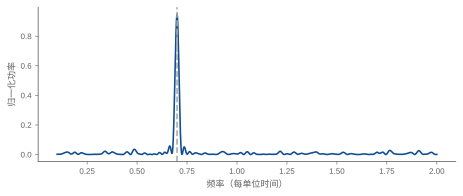

In [5]:
times = np.sort(rng.uniform(0, 40, 350))
true_frequency = 0.7
signal = 1.2 * np.sin(2 * np.pi * true_frequency * times) + rng.normal(0, 0.2, len(times))
frequency = np.linspace(0.1, 2, 1800)
power = lombscargle(times, signal, 2 * np.pi * frequency, floating_mean=True, normalize=True)
print("估计频率/已知频率:", frequency[np.argmax(power)], true_frequency)
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot(frequency, power, color=BLUE)
ax.axvline(true_frequency, color=GRAY, ls="--")
ax.set(xlabel="频率（每单位时间）", ylabel="归一化功率")
fig.tight_layout()
plt.show()
assert abs(frequency[np.argmax(power)] - true_frequency) < 0.01

读法：API 接受角频率，必须乘 2π；峰的显著性还受采样窗、混叠和扫描频率范围影响。谱峰本身不证明周期机制。

## 小结

时间序列分析从真实时刻和依赖结构开始。分解帮助描述，窗口服务明确的预测时刻，变化点对应指定的机制变化。采样计划影响能够识别什么，任何平滑、重采样和时间变换都应作为模型假设记录下来。